<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


## Assignment: Exploring and Preparing Data


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage.

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans.


## Objectives

Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

*   Exploratory Data Analysis
*   Preparing Data  Feature Engineering


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab


In [1]:
import piplite
await piplite.install(['numpy'])
await piplite.install(['pandas'])
await piplite.install(['seaborn'])

In [2]:
# pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

<ipython-input-2-cde6ab162d36>:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Exploratory Data Analysis


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [3]:
from js import fetch
import io

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
resp = await fetch(URL)
dataset_part_2_csv = io.BytesIO((await resp.arrayBuffer()).to_py())
df=pd.read_csv(dataset_part_2_csv)
df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass also appears to be a factor; even with more massive payloads, the first stage often returns successfully.


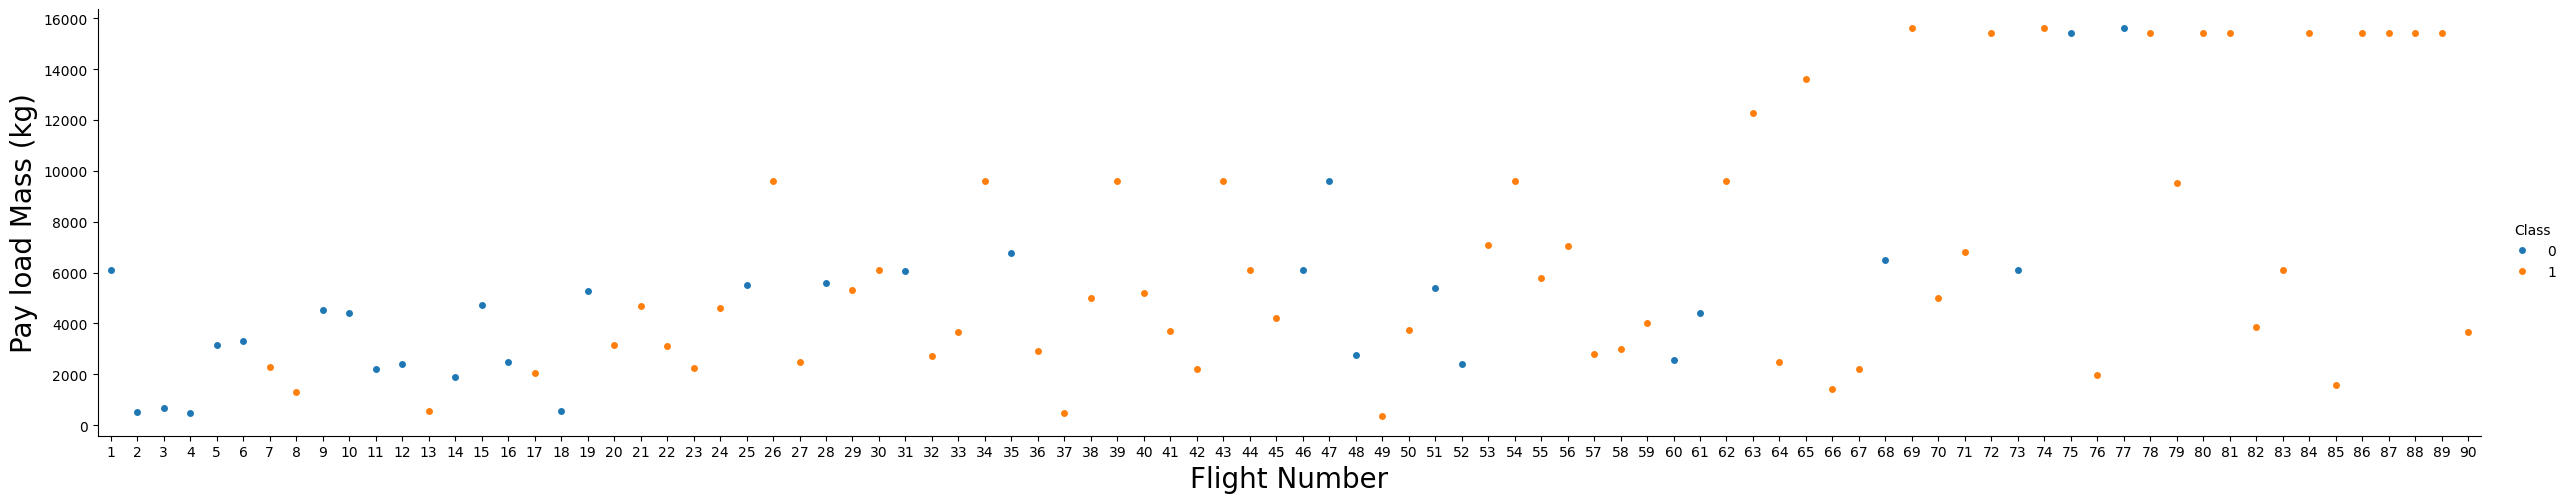

In [4]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.show()

Next, let's drill down to each site visualize its detailed launch records.


### ZADANIE 1: Wizualizacja zależności między numerem lotu a miejscem startu

Użyj funkcji <code>catplot</code>, aby wykreślić zależność między <code>FlightNumber</code> a <code>LaunchSite</code>; ustaw parametr <code>x</code> na <code>FlightNumber</code>, parametr <code>y</code> na <code>LaunchSite</code>, a parametr <code>hue</code> na <code>'class'</code>.


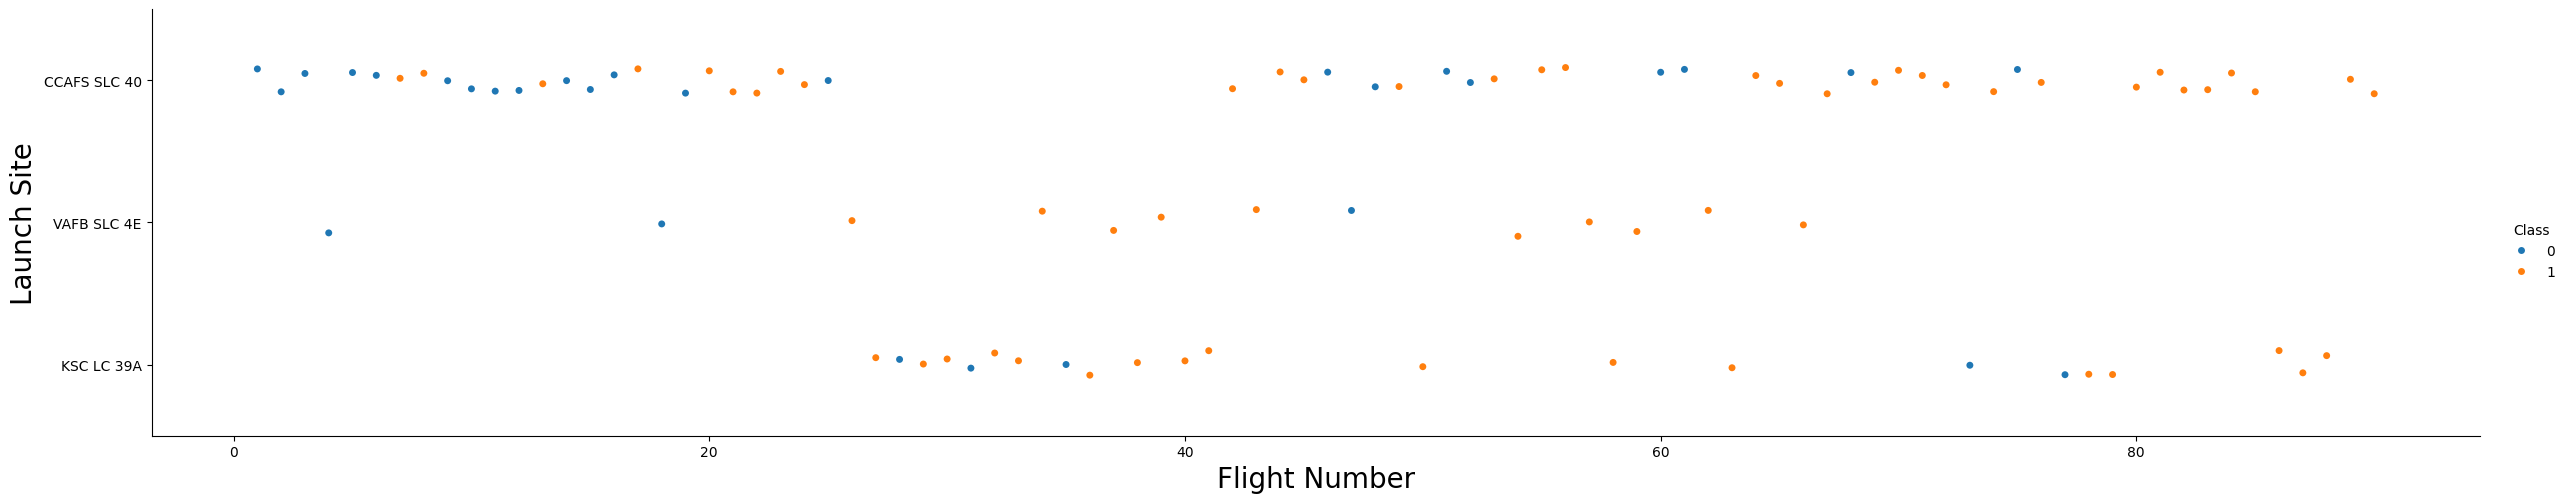

In [7]:
# Wygeneruj wykres punktowy (scatter plot), w którym oś x odpowiada numerowi lotu (Flight Number), oś y – miejscu startu (launch site), a kolor punktów (hue) – wartości klasy (class value)
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect = 5)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Launch Site",fontsize=20)
plt.show()

Spróbuj teraz wyjaśnić wzorce, które udało Ci się zaobserwować na wykresach punktowych przedstawiających zależność między numerem lotu a miejscem startu.


### ZADANIE 2: Wizualizacja zależności między masą ładunku a miejscem startu

Chcemy również sprawdzić, czy istnieje jakikolwiek związek między miejscami startu a masą ładunku.

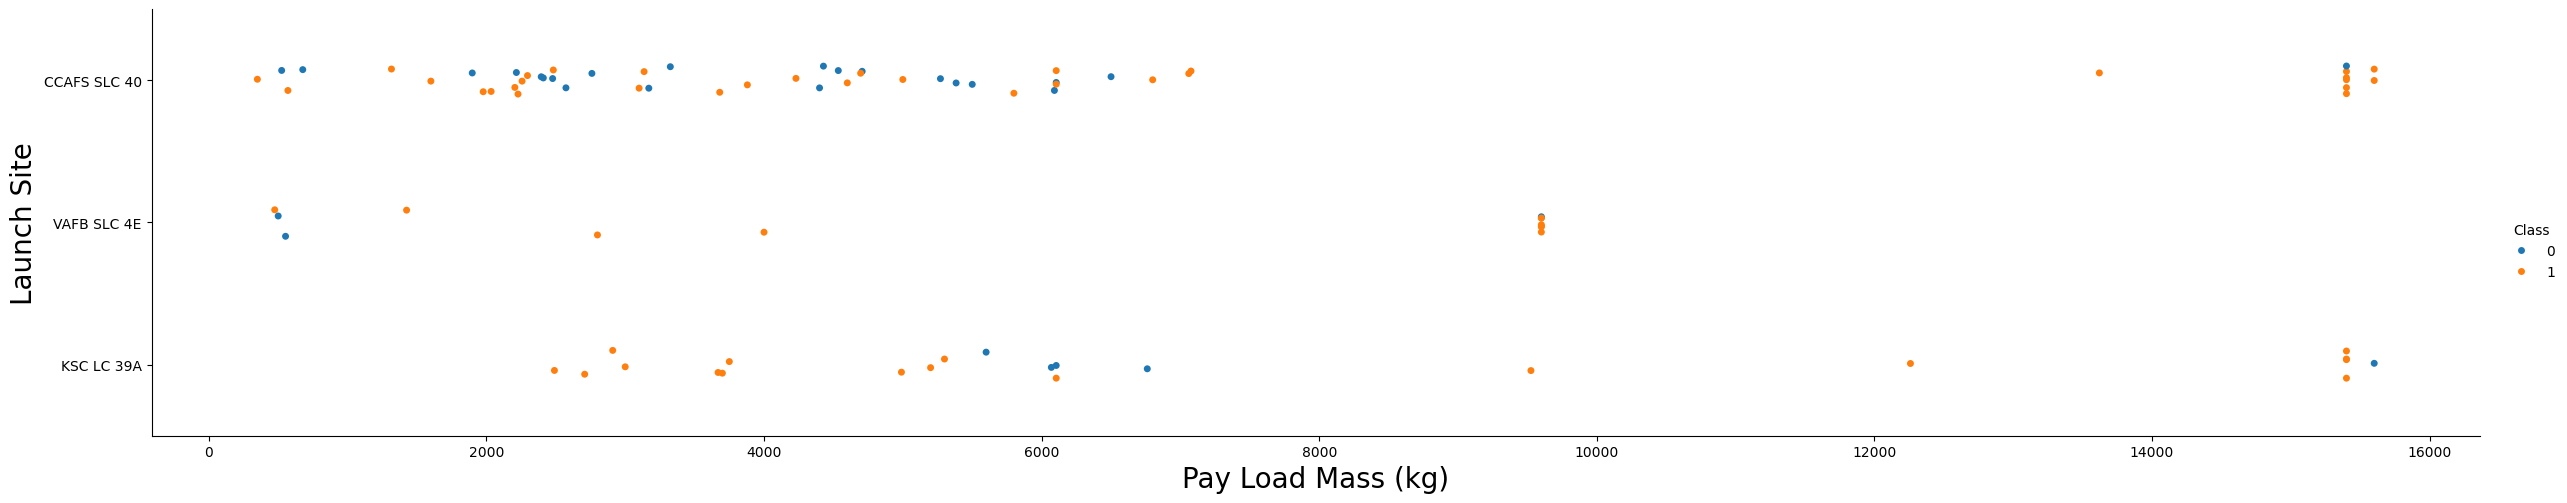

In [8]:
# Wygeneruj wykres punktowy (scatter plot), w którym oś x przedstawia masę ładunku (Pay Load Mass w kg), oś y – miejsce startu (launch site), a kolor punktów (hue) odpowiada wartości klasy (class value)
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect = 5)
plt.xlabel("Pay Load Mass (kg)",fontsize=20)
plt.ylabel("Launch Site",fontsize=20)
plt.show()

Jeśli przyjrzymy się wykresowi punktowemu przedstawiającemu zależność masy ładunku od miejsca startu, zauważymy, że w przypadku stanowiska startowego VAFB-SLC nie odnotowano żadnych startów rakiet z ładunkiem o dużej masie (powyżej 10 000).


### ZADANIE 3: Wizualizacja zależności między wskaźnikiem sukcesu dla poszczególnych typów orbit

Następnie chcemy sprawdzić wizualnie, czy istnieje jakikolwiek związek między wskaźnikiem sukcesu a typem orbity.

Stwórzmy wykres słupkowy przedstawiający wskaźnik sukcesów dla każdej orbity.

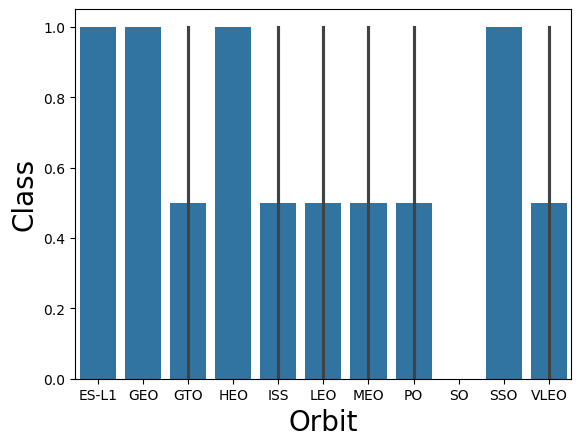

In [10]:
# WSKAZÓWKA: użyj metody groupby dla kolumny Orbit i oblicz średnią dla kolumny Class
t = df.groupby(['Orbit', 'Class'])['Class'].agg(['mean']).reset_index()
sns.barplot(y="Class", x="Orbit", data=t)

plt.xlabel("Orbit",fontsize=20)
plt.ylabel("Class",fontsize=20)
plt.show()

Przeanalizuj przedstawiony wykres słupkowy, aby ustalić, które orbity charakteryzują się najwyższymi wskaźnikami powodzenia.

### ZADANIE 4: Wizualizacja zależności między numerem lotu (FlightNumber) a typem orbity (Orbit)

Dla każdej orbity chcemy sprawdzić, czy istnieje jakakolwiek zależność między numerem lotu (FlightNumber) a typem orbity (Orbit type).

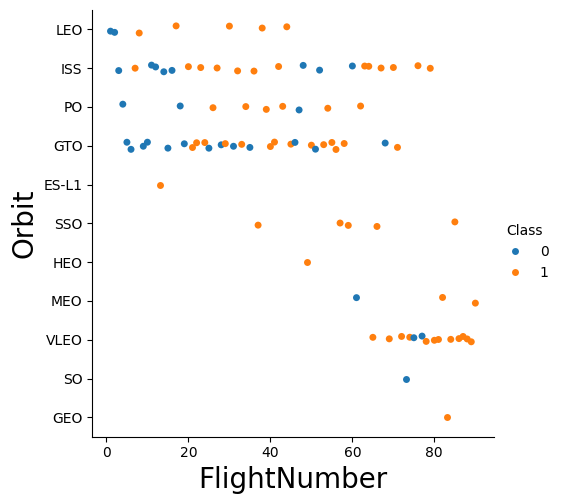

In [11]:
# Wygeneruj wykres punktowy (scatter plot), w którym oś x odpowiada numerowi lotu (FlightNumber), oś y – orbicie (Orbit), a kolor punktów (hue) – wartości klasy (class)
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df)
plt.xlabel("FlightNumber",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

Można zauważyć, że na orbicie LEO sukces wydaje się być powiązany z liczbą lotów. Z kolei na orbicie GTO nie widać żadnego związku między liczbą lotów a sukcesem.

### ZADANIE 5: Wizualizacja zależności między masą ładunku a typem orbity

Podobnie możemy sporządzić wykresy punktowe przedstawiające zależność między masą ładunku użytecznego a rodzajem orbity.

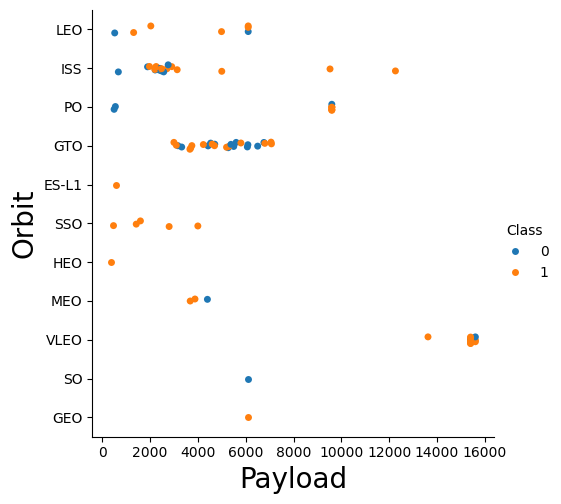

In [13]:
# Wygeneruj wykres punktowy (scatter plot), w którym oś x odpowiada masie ładunku (Payload Mass), oś y – orbicie (Orbit), a kolor punktów (hue) jest określony przez wartość klasy (class)
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df)
plt.xlabel("Payload",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

W przypadku ciężkich ładunków, wskaźnik udanych lądowań lub dodatnich lądowań jest większy w przypadku Polar, LEO i ISS.

Jednak w przypadku GTO trudno jest rozróżnić udane lądowania od nieudanych, ponieważ oba przypadki występują.

### ZADANIE 6: Wizualizacja rocznego trendu sukcesów startów

Możesz wykreślić wykres liniowy, w którym na osi x znajdzie się <code>Year</code> (rok), a na osi y – średni wskaźnik powodzenia, aby przedstawić trend średniej skuteczności startów.

Funkcja ta pomoże Ci uzyskać rok z daty:

In [14]:
# Funkcja wyodrębniająca lata z daty
year=[]
def Extract_year():
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
Extract_year()
df['Date'] = year
df.head()
    

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


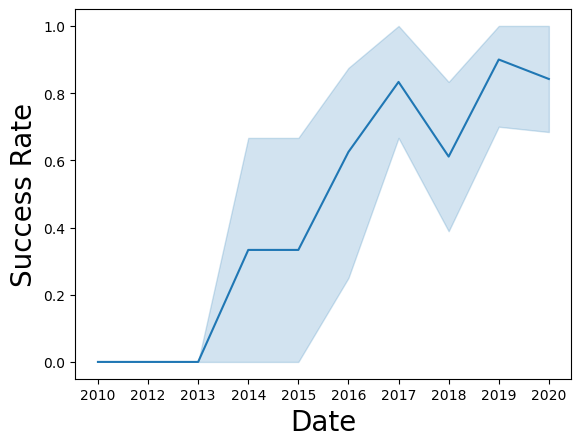

In [16]:
# Wykreśl wykres liniowy, w którym oś x przedstawia wyodrębniony rok, a oś y – wskaźnik sukcesu
sns.lineplot(data=df, x="Date", y="Class")
plt.xlabel("Date",fontsize=20)
plt.ylabel("Success Rate",fontsize=20)
plt.show()


Można zauważyć, że od 2013 roku wskaźnik sukcesu stale rósł aż do 2020 roku.

## Inżynieria cech

Na tym etapie powinieneś już dysponować wstępnymi wnioskami na temat tego, w jaki sposób poszczególne istotne zmienne wpływają na wskaźnik sukcesu; w kolejnym module wybierzemy cechy, które zostaną wykorzystane do prognozowania sukcesu.

In [17]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


### ZADANIE 7: Utwórz zmienne zero-jedynkowe (dummy variables) dla kolumn kategorycznych

Użyj funkcji <code>get_dummies</code> oraz ramki danych <code>features</code>, aby zastosować kodowanie typu „one-hot” (OneHotEncoder) dla kolumn <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code> oraz <code>Serial</code>. Przypisz wynik do zmiennej <code>features_one_hot</code> i wyświetl go za pomocą metody <code>head()</code>. Wynikowa ramka danych musi zawierać wszystkie cechy, w tym te poddane kodowaniu.

In [19]:
# WSKAZÓWKA: Użyj funkcji get_dummies() dla kolumn kategorycznych
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


### ZADANIE 8: Skonwertuj wszystkie kolumny liczbowe na typ `float64`

Skoro nasz obiekt DataFrame <code>features_one_hot</code> zawiera już tylko liczby, skonwertuj cały ten obiekt na typ danych <code>float64</code>.

In [20]:
# WSKAZÓWKA: użyj funkcji astype

We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range.


<code>features_one_hot.to_csv('dataset_part\_3.csv', index=False)</code>


## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log-->


<!--
| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|
| 2024-07-18        | 1.2     | Anita Verma | Clarified instructions|
-->


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
